# Demo FPT v2 — dùng đúng manifest

Notebook minh họa inference offline từ artifact v2. Ứng dụng UI sử dụng HTTP API nằm tại `src/app/streamlit_app.py`. Không load tên alias cũ, không tạo backtest giao dịch hoặc khuyến nghị mua/bán.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.metadata
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path('/content/FPT_Stock_Forecasting_portable_v2')
    if not (ROOT / '.git').exists():
        subprocess.check_call(['git', 'clone', '--depth', '1', '--branch', 'feature/train-model',
                               'https://github.com/PhucTruong11/FPT_Stock_Forecasting.git', str(ROOT)])
    loaded_versions = {name: getattr(sys.modules.get(name), '__version__', None)
                       for name in ['numpy', 'pandas', 'sklearn', 'tensorflow', 'xgboost']}
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements-colab.txt')])
    packages = {'sklearn': 'scikit-learn', 'numpy': 'numpy', 'pandas': 'pandas', 'tensorflow': 'tensorflow', 'xgboost': 'xgboost'}
    changed = [name for name, old in loaded_versions.items()
               if old is not None and old != importlib.metadata.version(packages[name])]
    if changed:
        raise RuntimeError('Dependencies changed: ' + str(changed) + '. Restart the Colab session, then Run all again.')
else:
    candidates = [Path(os.environ.get('FPT_PROJECT_ROOT', Path.cwd())), Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / 'src/models/experiment.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the complete updated project.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.snapshot import restore_snapshot
restore_snapshot(ROOT)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.models.experiment import load_data, split_masks, run_experiment, evaluate_saved
from src.features.build_features import FEATURE_COLUMNS, TARGET_COLUMN
plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('Project:', ROOT)
print('Exact shared snapshot restored; no Yahoo download.')


Project: D:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project
Exact shared snapshot restored; no Yahoo download.


In [2]:
from src.models.inference import ModelService
service = ModelService(ROOT)
print('Run:', service.manifest['run_id'])
print('Model thắng validation:', service.manifest['selection']['selected_model'])
print('Model ML mặc định để demo:', service.default_model)
display(pd.DataFrame(service.manifest['metrics']))

Run: 20261025T124951351761Z
Model thắng validation: Train Mean
Model ML mặc định để demo: LSTM


,model,split,n,rmse,mae,hit_rate_pct,nonzero_actual_n,neutral_actual_n,direction_coverage_pct,mse_skill_vs_zero
0,Zero-Return,validation,493,0.014095,0.010102,NaN,464,29,0.000000,0.000000
1,Return Persistence,validation,493,0.019069,0.014454,48.922414,464,29,94.612069,-0.830358
2,Train Mean,validation,493,0.013981,0.010076,54.741379,464,29,100.000000,0.016065
3,Always Up,validation,493,0.017470,0.014261,54.741379,464,29,100.000000,-0.536258
4,Linear Regression,validation,493,0.014051,0.010104,51.724138,464,29,100.000000,0.006176
5,Ridge,validation,493,0.014035,0.010085,50.646552,464,29,100.000000,0.008466
6,XGBoost,validation,493,0.014046,0.010060,56.034483,464,29,100.000000,0.006947
7,LSTM,validation,493,0.014033,0.009997,54.741379,464,29,100.000000,0.008832
8,Zero-Return,test,248,0.019917,0.013146,NaN,211,37,0.000000,0.000000
9,Return Persistence,test,248,0.027995,0.021221,36.018957,211,37,83.412322,-0.975684


## Lịch sử giá điều chỉnh

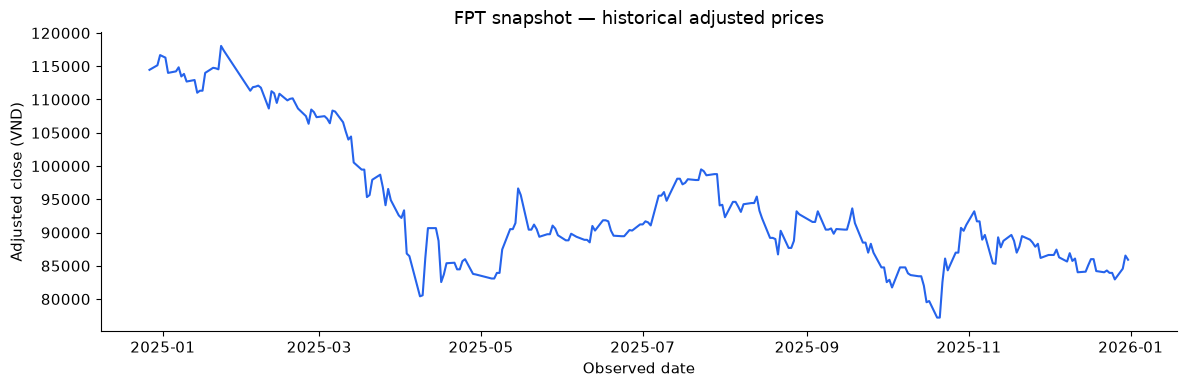

In [3]:
history = service.features.tail(252)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(history['Date'], history['Close'], color='#2563eb')
ax.set(xlabel='Observed date', ylabel='Adjusted close (VND)', title='FPT snapshot — historical adjusted prices')
fig.tight_layout()
plt.show()

## Dự báo một quan sát kế tiếp

Giá dữ liệu cuối là giá trong snapshot, không phải giá thị trường trực tiếp. Chưa có lịch HOSE xác minh nên không tự gán ngày đích.

In [4]:
import ipywidgets as widgets
from IPython.display import clear_output
selector = widgets.Dropdown(options=list(service.manifest['models']), value=service.default_model, description='Model:')
output = widgets.Output()
def render(change=None):
    with output:
        clear_output(wait=True)
        prediction = service.predict(selector.value)
        display(pd.Series(prediction))
selector.observe(render, names='value')
display(selector, output)
render()
assert service.predict('Zero-Return')['predicted_log_return'] == 0.0
print('Inference smoke check passed.')

Dropdown(description='Model:', index=7, options=('Zero-Return', 'Return Persistence', 'Train Mean', 'Always Up…

Output()

Inference smoke check passed.


## Kịch bản API/UI

1. Chạy `python -m uvicorn src.api.main:app --port 8000`.
2. Thử Swagger ở `http://127.0.0.1:8000/docs` với `{"model":"LSTM"}`.
3. Chạy `python -m streamlit run src/app/streamlit_app.py` và so sánh LSTM, Train Mean, Zero-Return.

LSTM là model ML dùng demo, không được gắn nhãn thắng toàn bộ vì Train Mean có RMSE validation thấp hơn.